In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

In [3]:
data = pd.read_csv("bluegills.txt", sep="\t")
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 78 entries, 0 to 77
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   age     78 non-null     int64
 1   length  78 non-null     int64
dtypes: int64(2)
memory usage: 1.3 KB


In [4]:
x = data["age"].values
y = data["length"].values
x = x.reshape(-1,1)
y = y.reshape(-1,1)
print(x.shape)
print(y.shape)

(78, 1)
(78, 1)


In [5]:
lin_reg = LinearRegression()
lin_reg.fit(x, y)
y_pred_lin = lin_reg.predict(x)

mse = mean_squared_error(y, y_pred_lin)
rmse = np.sqrt(mse)
r2 = r2_score(y, y_pred_lin)

print("Intercept:", lin_reg.intercept_)
print("Coefficient:", lin_reg.coef_[0])
print("MSE:", mse)
print("RMSE:", rmse)
print("R² Score:", r2)


Intercept: [62.64898354]
Coefficient: [22.31229429]
MSE: 152.47226648794904
RMSE: 12.347966087090985
R² Score: 0.7348821471782518


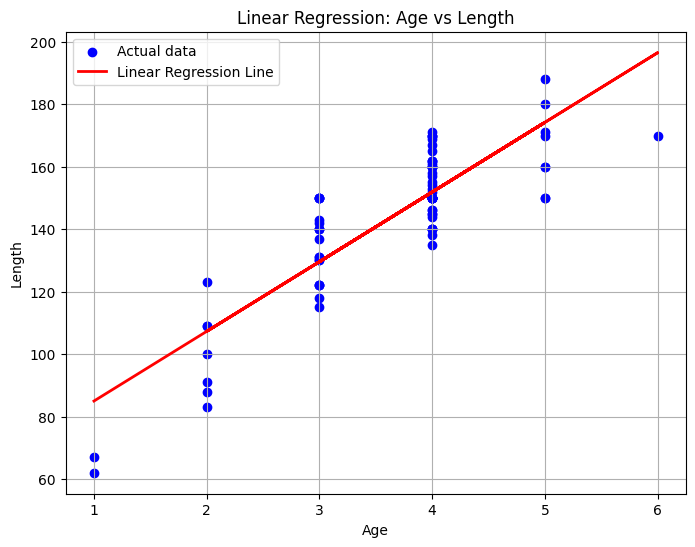

In [6]:
plt.figure(figsize=(8, 6))
plt.scatter(x, y, color="blue", label="Actual data")
plt.plot(x, y_pred_lin, color="red", linewidth=2, label="Linear Regression Line")

plt.xlabel("Age")
plt.ylabel("Length")
plt.title("Linear Regression: Age vs Length")
plt.legend()
plt.grid(True)
plt.show()

In [7]:
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

train_errors, test_errors = [], []

for degree in range(1, 11):
    poly = PolynomialFeatures(degree=degree)
    X_poly_train = poly.fit_transform(X_train)
    X_poly_test = poly.transform(X_test)

    model = LinearRegression()
    model.fit(X_poly_train, y_train)

    y_train_pred = model.predict(X_poly_train)
    y_test_pred = model.predict(X_poly_test)

    train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
    test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

    train_errors.append(train_rmse)
    test_errors.append(test_rmse)


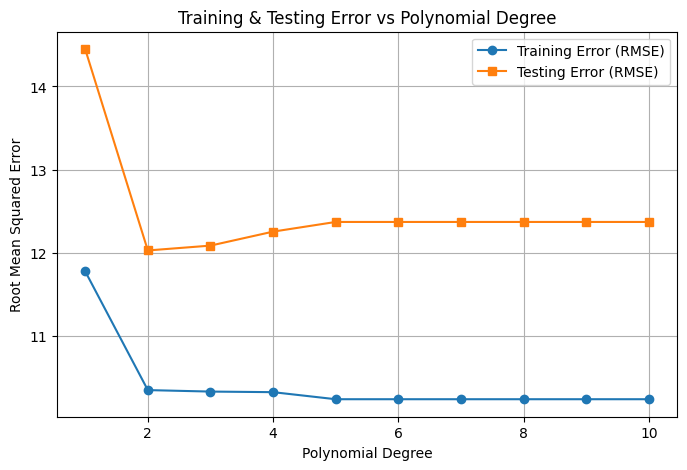

In [8]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), train_errors, marker='o', label="Training Error (RMSE)")
plt.plot(range(1, 11), test_errors, marker='s', label="Testing Error (RMSE)")
plt.xlabel("Polynomial Degree")
plt.ylabel("Root Mean Squared Error")
plt.title("Training & Testing Error vs Polynomial Degree")
plt.legend()
plt.grid(True)
plt.show()

In [16]:
poly = PolynomialFeatures(degree=3)
X_poly = poly.fit_transform(x)

poly_model = LinearRegression()
poly_model.fit(X_poly, y)
y_pred_poly = poly_model.predict(X_poly)

mse_lin = mean_squared_error(y, y_pred_lin)
mse_poly = mean_squared_error(y, y_pred_poly)

print(f"Linear Regression MSE: {mse_lin}")
print(f"Polynomial Regression MSE: {mse_poly}")

Linear Regression MSE: 152.47226648794904
Polynomial Regression MSE: 114.30392579532992


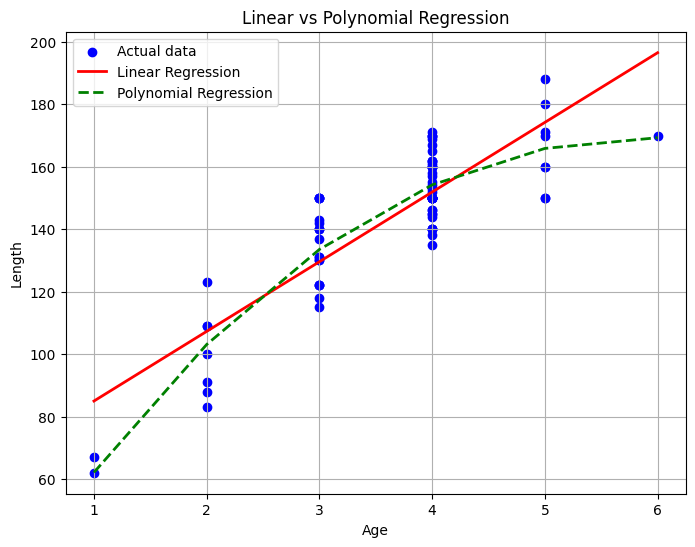

In [22]:
x_sorted = np.sort(x, axis=0)
y_lin_sorted = lin_reg.predict(x_sorted)

X_poly_sorted = poly.fit_transform(x_sorted)
y_poly_sorted = poly_model.predict(X_poly_sorted)

plt.figure(figsize=(8, 6))
plt.scatter(x, y, color="blue", label="Actual data")
plt.plot(x_sorted, y_lin_sorted, color="red", linewidth=2, label="Linear Regression")
plt.plot(x_sorted, y_poly_sorted, color="green", linewidth=2, linestyle="--", label="Polynomial Regression")

plt.xlabel("Age")
plt.ylabel("Length")
plt.title("Linear vs Polynomial Regression")
plt.legend()
plt.grid(True)
plt.show()


In [18]:
r2 = r2_score(y, y_pred_lin)
print(f"R² = {r2:.4f} ")

R² = 0.7349 


In [27]:
nifty_50 = pd.read_csv("/content/NIFTY 50.csv")
bank_df = pd.read_csv("/content/NIFTY BANK.csv")
nifty_midcap = pd.read_csv("/content/NIFTY MIDCAP.csv")
energy_df = pd.read_csv("/content/NIFTY ENERGY.csv")

In [30]:
# Extract Date and Open
bank = bank_df[["Date", "Open"]].rename(columns={"Open": "Bank_Open"})
energy = energy_df[["Date", "Open"]].rename(columns={"Open": "Energy_Open"})

# Merge datasets on Date
merged = pd.merge(bank, energy, on="Date", how="inner")
merged["Date"] = pd.to_datetime(merged["Date"], format="%d-%b-%y")
merged = merged.sort_values("Date")

# Independent (Bank Nifty) and Dependent (Energy Nifty)
X = merged[["Bank_Open"]].values
y = merged["Energy_Open"].values

lin_reg = LinearRegression()
lin_reg.fit(X, y)
y_pred_lin = lin_reg.predict(X)
r2_lin = r2_score(y, y_pred_lin)

# ----------------------------
# Polynomial Regression (deg 2–5)
# ----------------------------
r2_scores = {"Linear": r2_lin}
poly_preds = {}

for degree in range(2, 6):
    poly = PolynomialFeatures(degree=degree)
    X_poly = poly.fit_transform(X)

    poly_model = LinearRegression()
    poly_model.fit(X_poly, y)
    y_pred_poly = poly_model.predict(X_poly)

    r2_scores[f"Degree {degree}"] = r2_score(y, y_pred_poly)
    poly_preds[degree] = (poly, poly_model)

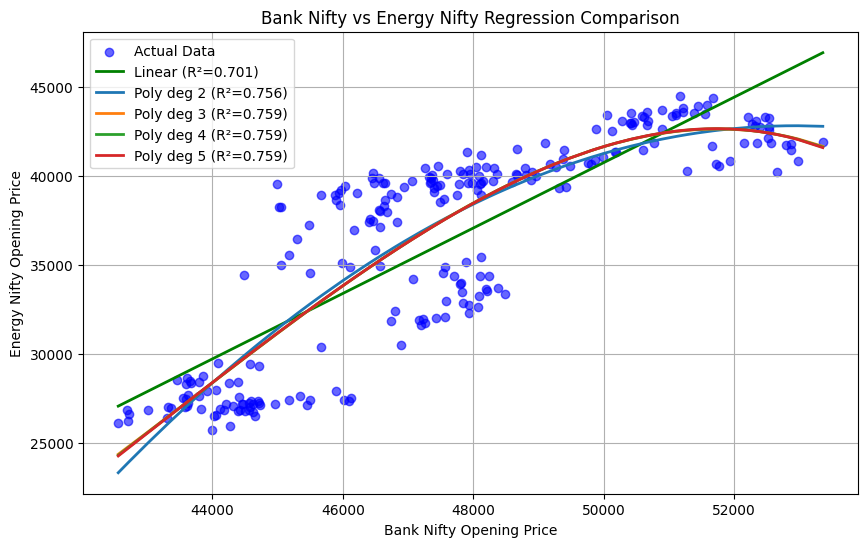

In [32]:
plt.figure(figsize=(10, 6))
plt.scatter(X, y, color="blue", alpha=0.6, label="Actual Data")

X_sorted = np.sort(X, axis=0)

plt.plot(X_sorted, lin_reg.predict(X_sorted),color="green", linewidth=2,label=f"Linear (R²={r2_lin:.3f})")

for degree, (poly, model) in poly_preds.items():
    X_poly_sorted = poly.transform(X_sorted)
    y_poly_sorted = model.predict(X_poly_sorted)
    plt.plot(X_sorted, y_poly_sorted, linewidth=2,
             label=f"Poly deg {degree} (R²={r2_scores[f'Degree {degree}']:.3f})")

plt.xlabel("Bank Nifty Opening Price")
plt.ylabel("Energy Nifty Opening Price")
plt.title("Bank Nifty vs Energy Nifty Regression Comparison")
plt.legend()
plt.grid(True)
plt.show()

In [29]:
print("R² Scores for Models:")
for model, score in r2_scores.items():
    print(f"{model}: {score:.4f}")

R² Scores for Models:
Linear: 0.7013
Degree 2: 0.7565
Degree 3: 0.7587
Degree 4: 0.7586
Degree 5: 0.7586
